---
title: "Rotation and Rigid Bodies — Level 2"
short_title: "09 Rigid Bodies"
numbering:
  heading_2: true
  equation: true
---

# Rotation and Rigid Bodies

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 9–10 | Rotation about a fixed axis with a scalar moment of inertia |
| **2** | **Taylor, ch. 10** | **Inertia tensor, principal axes, angular momentum not parallel to ω, Euler's equations** |
| 3 | Goldstein, ch. 5 | Euler angles, the heavy symmetric top, nutation |

The new skill at this level: treating the moment of inertia as a tensor and finding the axes in which rotation is simple

Math for this topic: M6, linear algebra (eigenvalues, tensors).
:::

Builds on the angular momentum notes (fixed-axis rotation) and the noninertial-frames notes (rotating derivatives). Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, quad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
g = 9.81  # m/s^2

## The Inertia Tensor

Every point of a rigid body rotating with angular velocity $\boldsymbol\omega$ about a fixed point moves with $\mathbf{v} = \boldsymbol\omega\times\mathbf{r}$. Its total angular momentum is

$$
\mathbf{L} = \sum_\alpha m_\alpha\,\mathbf{r}_\alpha\times(\boldsymbol\omega\times\mathbf{r}_\alpha) = \sum_\alpha m_\alpha\left[r_\alpha^2\boldsymbol\omega - (\mathbf{r}_\alpha\cdot\boldsymbol\omega)\,\mathbf{r}_\alpha\right]
$$

by the BAC–CAB rule from M1. This is linear in $\boldsymbol\omega$, so it is a matrix times $\boldsymbol\omega$:

$$
\mathbf{L} = \mathbf{I}\,\boldsymbol\omega, \qquad I_{ij} = \sum_\alpha m_\alpha\left(r_\alpha^2\,\delta_{ij} - x_{\alpha i}\,x_{\alpha j}\right) .
$$ (eq-inertia-tensor)

Written out, the diagonal entries are the familiar moments of inertia ($I_{xx} = \sum m(y^2 + z^2)$), and the off-diagonal **products of inertia** are $I_{xy} = -\sum m\,xy$ and so on. For a continuous body, replace the sum by $\int\rho\,dV$ (M2). The tensor is symmetric.

:::{important} $\mathbf{L}$ need not be parallel to $\boldsymbol\omega$
If the products of inertia are not zero, $\mathbf{I}\boldsymbol\omega$ points in a different direction from $\boldsymbol\omega$. As the body turns, $\mathbf{L}$ is carried around with it, so $\mathbf{L}$ changes, and keeping such a body spinning at constant $\boldsymbol\omega$ needs a **torque**. That is why an unbalanced car wheel shakes its axle.
:::

The kinetic energy is $T = \tfrac12\boldsymbol\omega\cdot\mathbf{L} = \tfrac12\boldsymbol\omega^{\mathsf T}\mathbf{I}\,\boldsymbol\omega$.

::::{prf:example} A tilted dumbbell
:label: ex-tilted-dumbbell

Two masses $m$ are fixed at the ends of a massless rod of length $d$, centered on the origin and tilted at angle $\alpha$ from the $z$-axis. The rod spins about $z$ with constant $\omega$. Find $\mathbf{L}$ and the torque the bearings must supply.

:::{dropdown} Solution
At the instant the rod lies in the $xz$-plane, the masses are at $\pm\mathbf{r}_0$ with $\mathbf{r}_0 = \tfrac d2\langle\sin\alpha, 0, \cos\alpha\rangle$. With $\boldsymbol\omega = \omega\hat{\mathbf{z}}$,

$$
\mathbf{L} = 2m\left[r_0^2\boldsymbol\omega - (\mathbf{r}_0\cdot\boldsymbol\omega)\mathbf{r}_0\right] = \frac{md^2\omega}{2}\sin\alpha\,\langle-\cos\alpha,\ 0,\ \sin\alpha\rangle .
$$

$\mathbf{L}$ is perpendicular to the rod, not along $\boldsymbol\omega$. It rotates with the rod, so $\dot{\mathbf{L}} = \boldsymbol\omega\times\mathbf{L}$, with magnitude

$$
|\boldsymbol\Gamma| = \frac{md^2\omega^2}{2}\sin\alpha\cos\alpha .
$$

The torque vanishes only when $\alpha = 0$ or $90^\circ$, which are the principal axes of the dumbbell.
:::
::::

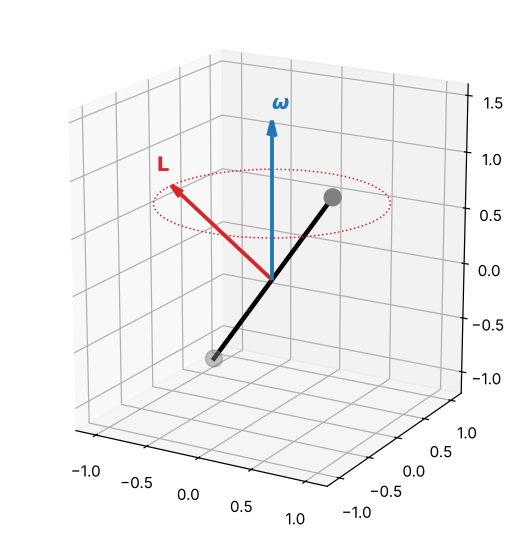

L = [-0.9397  0.      0.658 ] | angle between L and omega: 55.0 deg


In [2]:
#| label: fig-dumbbell
#| caption: The tilted dumbbell. The angular velocity (blue) is vertical, but the angular momentum (red) is perpendicular to the rod and sweeps around a cone as the rod turns, so a torque is needed.
alpha, d, m, w = np.radians(35), 2.0, 1.0, 1.0
r0 = d / 2 * np.array([np.sin(alpha), 0, np.cos(alpha)])
L = 2 * m * (r0 @ r0 * np.array([0, 0, w]) - (r0 @ np.array([0, 0, w])) * r0)
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection="3d")
ax.plot(*np.c_[-r0, r0], "k-", lw=3)
ax.scatter(*np.c_[-r0, r0], s=120, color="gray")
ax.quiver(0, 0, 0, 0, 0, 1.4, color="tab:blue", lw=2.5, arrow_length_ratio=0.1)
ax.text(0, 0, 1.5, r"$\boldsymbol{\omega}$", color="tab:blue", fontsize=13)
Ln = 1.2 * L / np.linalg.norm(L)
ax.quiver(0, 0, 0, *Ln, color="tab:red", lw=2.5, arrow_length_ratio=0.1)
ax.text(*(Ln * 1.15), r"$\mathbf{L}$", color="tab:red", fontsize=13)
ph = np.linspace(0, 2 * np.pi, 100)
rad = np.hypot(Ln[0], Ln[1])
ax.plot(rad * np.cos(ph + np.pi), rad * np.sin(ph + np.pi), Ln[2] + 0 * ph, "tab:red", ls=":", lw=1)
ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_zlim(-1.2, 1.6); ax.set_box_aspect((1, 1, 1.15))
ax.view_init(elev=18, azim=-60); plt.show()
print("L =", np.round(L, 4), "| angle between L and omega:", round(np.degrees(np.arccos(L[2] / np.linalg.norm(L))), 1), "deg")

## Principal Axes

Because $\mathbf{I}$ is real and symmetric, M6 guarantees three perpendicular axes, its **eigenvectors**, along which it is diagonal:

$$
\mathbf{I}\,\mathbf{e}_i = \lambda_i\,\mathbf{e}_i .
$$

These are the **principal axes**, and the eigenvalues $\lambda_1, \lambda_2, \lambda_3$ are the **principal moments**. Spinning a body about a principal axis gives $\mathbf{L}$ parallel to $\boldsymbol\omega$, and in principal-axis components

$$
\mathbf{L} = \langle\lambda_1\omega_1,\ \lambda_2\omega_2,\ \lambda_3\omega_3\rangle, \qquad T = \tfrac12\left(\lambda_1\omega_1^2 + \lambda_2\omega_2^2 + \lambda_3\omega_3^2\right) .
$$

Symmetry usually reveals the principal axes: any axis of rotational symmetry is one, and so is any axis perpendicular to a plane of mirror symmetry. When symmetry does not help, compute $\mathbf{I}$ and diagonalize it.

In [3]:
# Inertia tensor of a uniform box (sides a, b, c, mass M) about one corner, then its principal axes
x, y, z, a, b_, c, M = sp.symbols("x y z a b c M", positive=True)
rho = M / (a * b_ * c)
def box_int(f):
    return sp.integrate(rho * f, (x, 0, a), (y, 0, b_), (z, 0, c))
r = sp.Matrix([x, y, z])
I = sp.Matrix(3, 3, lambda i, j: box_int((r.dot(r) if i == j else 0) - r[i] * r[j]))
print("I (about corner) =", sp.simplify(I))

vals = {a: 1, b_: 2, c: 3, M: 1}
lam, vecs = np.linalg.eigh(np.array(I.subs(vals), dtype=float))
print("principal moments:", np.round(lam, 4))
print("principal axes (columns):\n", np.round(vecs, 3))

I (about corner) = Matrix([[M*(b**2 + c**2)/3, -M*a*b/4, -M*a*c/4], [-M*a*b/4, M*(a**2 + c**2)/3, -M*b*c/4], [-M*a*c/4, -M*b*c/4, M*(a**2 + b**2)/3]])
principal moments: [0.5689 4.2088 4.5556]
principal axes (columns):
 [[ 0.233 -0.139 -0.963]
 [ 0.496 -0.834  0.24 ]
 [ 0.837  0.533  0.125]]


### Exercises

1. A uniform square plate of side $a$ and mass $M$ lies in the $xy$-plane, centered on the origin. Find its principal moments about the center. What is its moment of inertia about a diagonal?
2. Show that for any flat body in the $xy$-plane, $I_{zz} = I_{xx} + I_{yy}$ (the perpendicular-axis theorem) follows from {eq}`eq-inertia-tensor`.
3. Use the code above to find the principal moments of a uniform cube of side $1$ and mass $1$ about a corner. Which direction is the special axis?

:::{dropdown} Hints
1. By symmetry $I_{xx} = I_{yy}$; use the perpendicular-axis theorem for $I_{zz}$.
2. Set $z = 0$ in the integrands.
3. Set $a = b = c = 1$. One eigenvalue is different from the other two.
:::

:::{dropdown} Answers
1. $I_{xx} = I_{yy} = Ma^2/12$ and $I_{zz} = Ma^2/6$. Since $I_{xx} = I_{yy}$, every in-plane axis through the center is principal, so the diagonal also gives $Ma^2/12$.
2. With $z = 0$, $I_{xx} = \sum my^2$, $I_{yy} = \sum mx^2$ and $I_{zz} = \sum m(x^2 + y^2)$.
3. $1/6$ along the body diagonal $\langle1,1,1\rangle/\sqrt3$, and $11/12$ (twice) for any axis perpendicular to it.
:::

## Euler's Equations

The torque equation $\dot{\mathbf{L}} = \boldsymbol\Gamma$ holds in an inertial frame. It is easier to work in a frame attached to the body, aligned with its principal axes, where $\mathbf{I}$ is constant and diagonal. By the rotating-derivative rule from the noninertial-frames notes,

$$
\left(\frac{d\mathbf{L}}{dt}\right)_{\text{body}} + \boldsymbol\omega\times\mathbf{L} = \boldsymbol\Gamma .
$$

With $\mathbf{L} = \langle\lambda_1\omega_1, \lambda_2\omega_2, \lambda_3\omega_3\rangle$, the components give **Euler's equations**:

$$
\begin{aligned}
\lambda_1\dot\omega_1 - (\lambda_2 - \lambda_3)\,\omega_2\omega_3 &= \Gamma_1, \\
\lambda_2\dot\omega_2 - (\lambda_3 - \lambda_1)\,\omega_3\omega_1 &= \Gamma_2, \\
\lambda_3\dot\omega_3 - (\lambda_1 - \lambda_2)\,\omega_1\omega_2 &= \Gamma_3 .
\end{aligned}
$$ (eq-euler-equations)

They are nonlinear, but two torque-free cases are solvable and physically important.

### A symmetric body: wobble

For a body with $\lambda_1 = \lambda_2$ (a coin, a rugby ball, the Earth), the third equation gives $\omega_3 = $ constant. The other two become

$$
\dot\omega_1 = -\Omega_b\,\omega_2, \qquad \dot\omega_2 = \Omega_b\,\omega_1, \qquad \Omega_b = \frac{\lambda_3 - \lambda_1}{\lambda_1}\,\omega_3 .
$$

This is the rotating-vector equation again: seen from the body, $\boldsymbol\omega$ circles the symmetry axis at rate $\Omega_b$. For the Earth, $(\lambda_3 - \lambda_1)/\lambda_1\approx1/305$, so a rigid Earth would wobble with a period of about 305 days. The observed **Chandler wobble** has a period of about 433 days; the difference comes from the Earth not being rigid.

### Stability of free rotation

Try spinning a body about principal axis 1, with tiny components $\omega_2$, $\omega_3$. To first order, $\omega_1$ stays constant, and differentiating the second equation and substituting the third gives

$$
\ddot\omega_2 = \frac{(\lambda_3 - \lambda_1)(\lambda_1 - \lambda_2)}{\lambda_2\lambda_3}\,\omega_1^2\,\omega_2 .
$$

The perturbation oscillates (stable) if the coefficient is negative, which happens when $\lambda_1$ is either the **largest** or the **smallest** principal moment. If $\lambda_1$ is the **intermediate** moment, the coefficient is positive and the perturbation grows exponentially. This is the tennis-racket (intermediate-axis) effect: a racket, a phone, or a book tossed spinning about its middle axis flips over repeatedly.

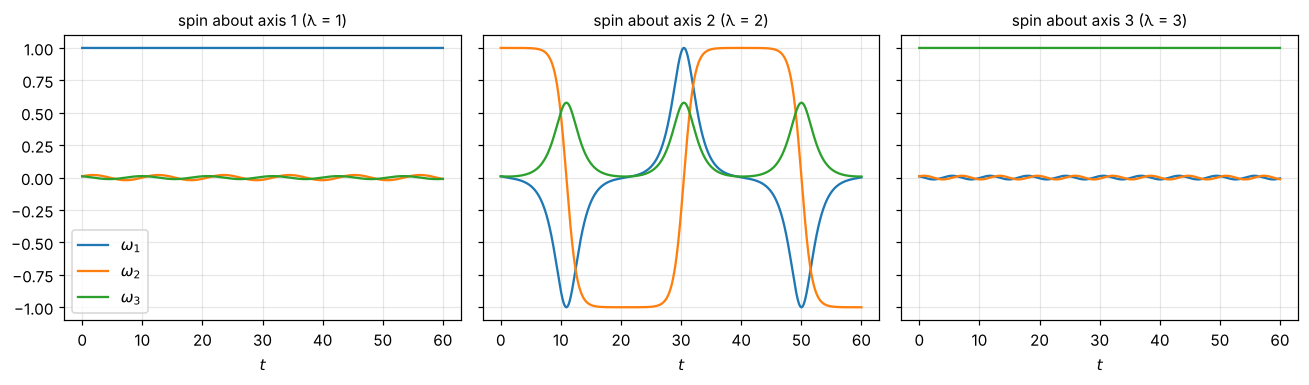

In [4]:
#| label: fig-intermediate-axis
#| caption: Torque-free Euler's equations for a body with λ = (1, 2, 3), started spinning almost exactly about each principal axis. Spins about the smallest and largest axes stay put; the spin about the intermediate axis (middle) repeatedly flips sign.
lam = np.array([1.0, 2.0, 3.0])
def euler(t, w):
    w1, w2, w3 = w
    return [(lam[1] - lam[2]) * w2 * w3 / lam[0], (lam[2] - lam[0]) * w3 * w1 / lam[1], (lam[0] - lam[1]) * w1 * w2 / lam[2]]
t = np.linspace(0, 60, 4000)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for k, ax in enumerate(axes):
    w0 = np.full(3, 0.01); w0[k] = 1.0
    sol = solve_ivp(euler, (0, 60), w0, t_eval=t, rtol=1e-10, atol=1e-12)
    for i, c in enumerate(["tab:blue", "tab:orange", "tab:green"]):
        ax.plot(t, sol.y[i], color=c, lw=1.5, label=rf"$\omega_{i+1}$")
    ax.set_title(f"spin about axis {k + 1} (λ = {lam[k]:.0f})", fontsize=10); ax.set_xlabel("$t$")
axes[0].legend(); plt.tight_layout(); plt.show()

## A Glimpse of the Spinning Top

A top spinning fast about its symmetry axis, tilted and pivoted at its tip, feels a gravitational torque of magnitude $MgR\sin\theta$ ($R$ = distance from tip to center of mass). The torque is horizontal and perpendicular to $\mathbf{L}$, so it swings $\mathbf{L}$ sideways rather than tipping it over. For a fast top, $L\approx\lambda_3\omega_3$ along the axis, and the axis **precesses** about the vertical at

$$
\Omega_{\text{pr}}\approx\frac{MgR}{\lambda_3\omega_3} .
$$

The faster the spin, the slower the precession. The full motion, including the nodding called **nutation**, needs Euler angles and a Lagrangian, which is the Level 3 rung of this topic.

### Exercises

1. For the tilted dumbbell, verify the torque magnitude by computing $|\boldsymbol\omega\times\mathbf{L}|$.
2. A coin spins about a diameter while also wobbling slightly. For a thin disk, $\lambda_3 = 2\lambda_1$ about its symmetry axis. Find $\Omega_b/\omega_3$.
3. A top with $M = 0.1$ kg, $R = 4$ cm, $\lambda_3 = 4\times10^{-5}$ kg·m² spins at 100 rev/s. Estimate its precession period.

:::{dropdown} Hints
1. $\boldsymbol\omega$ is along $z$; $\mathbf{L}$ has components $\propto\langle-\cos\alpha, 0, \sin\alpha\rangle$.
2. Use $\Omega_b = (\lambda_3 - \lambda_1)\omega_3/\lambda_1$.
3. $\omega_3 = 2\pi\times100$ rad/s.
:::

:::{dropdown} Answers
1. $|\omega\hat{\mathbf{z}}\times\mathbf{L}| = \omega\cdot\frac{md^2\omega}{2}\sin\alpha\cos\alpha$.
2. $\Omega_b = \omega_3$: seen from the coin, $\boldsymbol\omega$ circles the axis once per spin.
3. $\Omega_{\text{pr}} = (0.1)(9.81)(0.04)/(4\times10^{-5}\cdot628)\approx1.56$ rad/s, a period of about 4 s.
:::

## Summary

- For rotation about a fixed point, $\mathbf{L} = \mathbf{I}\boldsymbol\omega$ with the symmetric inertia tensor {eq}`eq-inertia-tensor`; in general $\mathbf{L}\nparallel\boldsymbol\omega$.
- The eigenvectors of $\mathbf{I}$ are the principal axes. About them, $\mathbf{L}\parallel\boldsymbol\omega$ and both $\mathbf{L}$ and $T$ take diagonal form.
- Euler's equations {eq}`eq-euler-equations` give the rotation in the body frame.
- A torque-free symmetric body wobbles at $\Omega_b = (\lambda_3 - \lambda_1)\omega_3/\lambda_1$; the Earth's version is the Chandler wobble.
- Free rotation is stable about the largest and smallest principal axes and unstable about the intermediate one.
- A fast top precesses at $MgR/(\lambda_3\omega_3)$.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.